# 03 — Covariate quality and leakage audit

This notebook creates the canonical daily feature panel and determines which variables may enter the global daily model.

The daily prediction rule is strict: **a feature is safe only if it is known by the end of the previous trading day or is known in advance from the calendar**. Current-day CRSP outcomes, intraday trades, auction fields, and final daily volume are excluded from the daily model.

The resulting panel retains targets and diagnostic fields for analysis, but the approved model-feature list is stored separately and explicitly.

In [1]:
from pathlib import Path
import json
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 6), "figure.dpi": 120})

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "blackrock_data").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate blackrock_data.")

DATA = PROJECT_ROOT / "blackrock_data"
OUT = PROJECT_ROOT / "outputs" / "eda" / "03_covariate_audit"
OUT.mkdir(parents=True, exist_ok=True)
PANEL_PATH = OUT / "daily_covariate_panel.parquet"

AUCTION = str(DATA / "stock_daily/auction_daily/year=*/auction_daily_*.parquet")
CRSP = str(DATA / "stock_daily/crsp_daily/year=*/crsp_daily_*.parquet")
MARKET = str(DATA / "market/market_daily.parquet")
EVENTS = str(DATA / "events/event_calendar.parquet")
INDUSTRY = str(DATA / "reference/industry_history.parquet")
ANOMALIES = str(DATA / "quality/auction_source_anomalies.parquet")

con = duckdb.connect()

def sql(query, params=None):
    return con.execute(query, params or []).df()

print(f"Project root: {PROJECT_ROOT}")

Project root: /Users/aramesh/Documents/Fall 2026/Capstone


## Information-time policy

The feature catalog is the contract for subsequent modeling notebooks. A field can be present in the panel for diagnostics without being approved as a model input.

In [2]:
catalog_rows = [
    ("lag1_auction_volume", "Auction history", "Previous observed closing-auction volume", "Previous close", "daily_safe", True),
    ("lag2_auction_volume", "Auction history", "Auction volume two trading observations earlier", "t-2", "daily_safe", True),
    ("lag5_auction_volume", "Auction history", "Auction volume five trading observations earlier", "t-5", "daily_safe", True),
    ("avg5_auction_volume", "Auction history", "Mean auction volume over five prior rows", "Through t-1", "daily_safe", True),
    ("median20_auction_volume", "Auction history", "Median auction volume over twenty prior rows", "Through t-1", "daily_safe", True),
    ("std20_auction_volume", "Auction history", "Auction-volume standard deviation over twenty prior rows", "Through t-1", "daily_safe", True),
    ("prior_auction_observations", "Auction history", "Number of observed prior auctions for the stock", "Through t-1", "daily_safe", True),
    ("lag1_daily_volume", "Liquidity", "Previous trading-day share volume", "Previous close", "daily_safe", True),
    ("avg20_daily_volume", "Liquidity", "Mean daily volume over twenty prior rows", "Through t-1", "daily_safe", True),
    ("lag1_return", "Returns", "Previous trading-day total return", "Previous close", "daily_safe", True),
    ("volatility20", "Returns", "Return standard deviation over twenty prior rows", "Through t-1", "daily_safe", True),
    ("lag1_market_cap", "Size", "Previous trading-day market capitalization", "Previous close", "daily_safe", True),
    ("lag1_market_return", "Market", "Previous value-weighted market return", "Previous close", "daily_safe", True),
    ("market_volatility20", "Market", "Market return standard deviation over twenty prior days", "Through t-1", "daily_safe", True),
    ("lag1_market_volume", "Market", "Previous total market volume", "Previous close", "daily_safe", True),
    ("is_monday", "Calendar", "Monday indicator", "Known in advance", "daily_safe", True),
    ("is_friday", "Calendar", "Friday indicator", "Known in advance", "daily_safe", True),
    ("is_last_trading_day_month", "Calendar", "Last trading day of month", "Known in advance", "daily_safe", True),
    ("is_last_trading_day_quarter", "Calendar", "Last trading day of quarter", "Known in advance", "daily_safe", True),
    ("monthly_options_expiry", "Calendar", "Monthly options expiry", "Known in advance", "daily_safe", True),
    ("quarterly_options_expiry", "Calendar", "Quarterly options expiry", "Known in advance", "daily_safe", True),
    ("is_early_close", "Calendar", "Scheduled early close", "Known in advance", "daily_safe", True),
    ("month", "Calendar", "Calendar month", "Known in advance", "daily_safe", True),
    ("day_of_week", "Calendar", "Trading weekday", "Known in advance", "daily_safe", True),
    ("ff12_code", "Industry", "Point-in-time Fama–French 12 industry", "Known by prediction date", "daily_safe", True),
    ("size_decile", "Size", "Daily decile formed from lagged market capitalization", "Previous close", "daily_safe", True),
    ("permno", "Identifier", "Permanent security identifier", "Known", "identifier", False),
    ("auction_volume", "Target", "Current closing-auction volume", "At close", "target", False),
    ("log1p_auction_volume", "Target", "Log-transformed current closing-auction volume", "At close", "target", False),
    ("auction_to_adv20", "Target diagnostic", "Current auction volume divided by trailing ADV", "At close", "target", False),
    ("current_daily_volume", "Current-day outcome", "Final current-day share volume", "After close", "daily_leakage", False),
    ("current_return", "Current-day outcome", "Final current-day return", "After close", "daily_leakage", False),
    ("current_close", "Current-day outcome", "Current-day closing price", "After close", "daily_leakage", False),
    ("auction_price", "Auction outcome", "Current auction clearing price", "At close", "daily_leakage", False),
    ("auction_share_daily_volume", "Target-derived", "Current auction volume divided by final daily volume", "After close", "daily_leakage", False),
    ("cum_volume", "Intraday", "Current-day cumulative volume at checkpoint", "Same day", "intraday_only", False),
    ("vwap", "Intraday", "Current-day VWAP at checkpoint", "Same day", "intraday_only", False),
]

catalog = pd.DataFrame(catalog_rows, columns=[
    "variable", "group", "definition", "information_time", "classification", "approved_daily_feature"
])
display(catalog)
catalog.to_csv(OUT / "feature_catalog.csv", index=False)

SAFE_FEATURES = catalog.loc[catalog["approved_daily_feature"], "variable"].tolist()
FORBIDDEN_DAILY = set(catalog.loc[catalog["classification"] == "daily_leakage", "variable"])
assert not FORBIDDEN_DAILY.intersection(SAFE_FEATURES)
print(f"Approved daily features: {len(SAFE_FEATURES)}")

,variable,group,definition,information_time,classification,approved_daily_feature
0,lag1_auction_volume,Auction history,Previous observed closing-auction volume,Previous close,daily_safe,True
1,lag2_auction_volume,Auction history,Auction volume two trading observations earlier,t-2,daily_safe,True
2,lag5_auction_volume,Auction history,Auction volume five trading observations earlier,t-5,daily_safe,True
3,avg5_auction_volume,Auction history,Mean auction volume over five prior rows,Through t-1,daily_safe,True
4,median20_auction_volume,Auction history,Median auction volume over twenty prior rows,Through t-1,daily_safe,True
5,std20_auction_volume,Auction history,Auction-volume standard deviation over twenty ...,Through t-1,daily_safe,True
6,prior_auction_observations,Auction history,Number of observed prior auctions for the stock,Through t-1,daily_safe,True
7,lag1_daily_volume,Liquidity,Previous trading-day share volume,Previous close,daily_safe,True
8,avg20_daily_volume,Liquidity,Mean daily volume over twenty prior rows,Through t-1,daily_safe,True
9,lag1_return,Returns,Previous trading-day total return,Previous close,daily_safe,True


Approved daily features: 26


## Build the canonical daily panel

All rolling calculations end at `1 PRECEDING`. CRSP history begins in 2011 so the 2015 modeling sample can use earlier daily-market history. Auction-history features naturally begin when the auction target begins.

In [3]:
panel_sql = f"""
WITH crsp AS (
    SELECT date, permno, ticker, close, daily_volume, return_total, market_cap_usd
    FROM read_parquet('{CRSP}', union_by_name=true, hive_partitioning=true)
), auction AS (
    SELECT date, permno, auction_volume, auction_price,
           auction_share_daily_volume, target_found
    FROM read_parquet('{AUCTION}', union_by_name=true, hive_partitioning=true)
), base AS (
    SELECT c.*,
           a.auction_volume, a.auction_price, a.auction_share_daily_volume,
           coalesce(a.target_found, false) AS target_found
    FROM crsp c LEFT JOIN auction a USING (date, permno)
), stock_history AS (
    SELECT *,
           lag(auction_volume, 1) OVER w AS lag1_auction_volume,
           lag(auction_volume, 2) OVER w AS lag2_auction_volume,
           lag(auction_volume, 5) OVER w AS lag5_auction_volume,
           avg(auction_volume) OVER w5 AS avg5_auction_volume,
           median(auction_volume) OVER w20 AS median20_auction_volume,
           stddev_samp(auction_volume) OVER w20 AS std20_auction_volume,
           count(auction_volume) OVER (
               PARTITION BY permno ORDER BY date ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING
           ) AS prior_auction_observations,
           lag(daily_volume, 1) OVER w AS lag1_daily_volume,
           avg(daily_volume) OVER w20 AS avg20_daily_volume,
           lag(return_total, 1) OVER w AS lag1_return,
           stddev_samp(return_total) OVER w20 AS volatility20,
           lag(market_cap_usd, 1) OVER w AS lag1_market_cap
    FROM base
    WINDOW
        w AS (PARTITION BY permno ORDER BY date),
        w5 AS (PARTITION BY permno ORDER BY date ROWS BETWEEN 5 PRECEDING AND 1 PRECEDING),
        w20 AS (PARTITION BY permno ORDER BY date ROWS BETWEEN 20 PRECEDING AND 1 PRECEDING)
), market_history AS (
    SELECT date,
           lag(market_return_vw, 1) OVER (ORDER BY date) AS lag1_market_return,
           stddev_samp(market_return_vw) OVER (
               ORDER BY date ROWS BETWEEN 20 PRECEDING AND 1 PRECEDING
           ) AS market_volatility20,
           lag(market_total_volume, 1) OVER (ORDER BY date) AS lag1_market_volume
    FROM read_parquet('{MARKET}')
), candidate AS (
    SELECT s.*,
           m.lag1_market_return, m.market_volatility20, m.lag1_market_volume,
           e.day_of_week, e.is_monday, e.is_friday,
           e.is_last_trading_day_month, e.is_last_trading_day_quarter,
           e.monthly_options_expiry, e.quarterly_options_expiry, e.is_early_close,
           i.ff12_code, i.ff12_name,
           coalesce(an.exclude_from_model, false) AS exclude_source_anomaly,
           row_number() OVER (
               PARTITION BY s.date, s.permno
               ORDER BY i.secinfostartdt DESC NULLS LAST, i.secinfoenddt DESC NULLS LAST
           ) AS industry_rank
    FROM stock_history s
    LEFT JOIN market_history m USING (date)
    LEFT JOIN read_parquet('{EVENTS}') e USING (date)
    LEFT JOIN read_parquet('{INDUSTRY}') i
      ON s.permno = i.permno
     AND s.date BETWEEN i.secinfostartdt AND i.secinfoenddt
    LEFT JOIN read_parquet('{ANOMALIES}') an USING (date)
    WHERE s.date >= DATE '2015-01-01'
), panel AS (
    SELECT date, permno, ticker,
           year(date) AS year, month(date) AS month,
           day_of_week,
           CASE WHEN date <= DATE '2021-12-31' THEN 'train'
                WHEN date <= DATE '2023-12-31' THEN 'validation'
                ELSE 'test' END AS sample_split,
           target_found AS observed_target,
           exclude_source_anomaly,
           target_found AND auction_volume IS NOT NULL
             AND NOT exclude_source_anomaly AS eligible_target,
           auction_volume,
           CASE WHEN auction_volume IS NOT NULL THEN ln(1 + auction_volume) END AS log1p_auction_volume,
           auction_volume / nullif(avg20_daily_volume, 0) AS auction_to_adv20,
           auction_price, auction_share_daily_volume,
           daily_volume AS current_daily_volume,
           return_total AS current_return,
           close AS current_close,
           lag1_auction_volume, lag2_auction_volume, lag5_auction_volume,
           avg5_auction_volume, median20_auction_volume, std20_auction_volume,
           prior_auction_observations,
           lag1_daily_volume, avg20_daily_volume, lag1_return, volatility20,
           lag1_market_cap,
           ntile(10) OVER (PARTITION BY date ORDER BY lag1_market_cap) AS size_decile,
           lag1_market_return, market_volatility20, lag1_market_volume,
           is_monday, is_friday, is_last_trading_day_month,
           is_last_trading_day_quarter, monthly_options_expiry,
           quarterly_options_expiry, is_early_close,
           ff12_code, ff12_name
    FROM candidate
    WHERE industry_rank = 1
)
SELECT * FROM panel
"""

escaped_path = str(PANEL_PATH).replace("'", "''")
con.execute(f"COPY ({panel_sql}) TO '{escaped_path}' (FORMAT PARQUET, COMPRESSION ZSTD)")
PANEL = str(PANEL_PATH)
panel_overview = sql(f"""
SELECT count(*) AS rows, count(DISTINCT date) AS trading_days,
       count(DISTINCT permno) AS securities,
       count(*) FILTER (WHERE eligible_target) AS eligible_targets,
       min(date) AS first_date, max(date) AS last_date
FROM read_parquet('{PANEL}')
""")
display(panel_overview)
print(f"Panel written to {PANEL_PATH} ({PANEL_PATH.stat().st_size / 2**20:,.1f} MB)")

,rows,trading_days,securities,eligible_targets,first_date,last_date
0,3594404,2766,2149,3499401,2015-01-02,2025-12-31


Panel written to /Users/aramesh/Documents/Fall 2026/Capstone/outputs/eda/03_covariate_audit/daily_covariate_panel.parquet (319.9 MB)


## Feature missingness

,feature,rows,missing,missing_rate,distinct_values,group,information_time
0,lag5_auction_volume,3594404,104673,0.0291,669072,Auction history,t-5
1,lag2_auction_volume,3594404,98560,0.0274,669598,Auction history,t-2
2,lag1_auction_volume,3594404,96531,0.0269,669847,Auction history,Previous close
3,avg5_auction_volume,3594404,60143,0.0167,1525869,Auction history,Through t-1
4,std20_auction_volume,3594404,51776,0.0144,3508543,Auction history,Through t-1
5,median20_auction_volume,3594404,33642,0.0094,559420,Auction history,Through t-1
6,volatility20,3594404,2172,0.0006,3587697,Returns,Through t-1
7,lag1_return,3594404,1424,0.0004,200512,Returns,Previous close
8,lag1_daily_volume,3594404,801,0.0002,2012306,Liquidity,Previous close
9,lag1_market_cap,3594404,801,0.0002,3199432,Size,Previous close


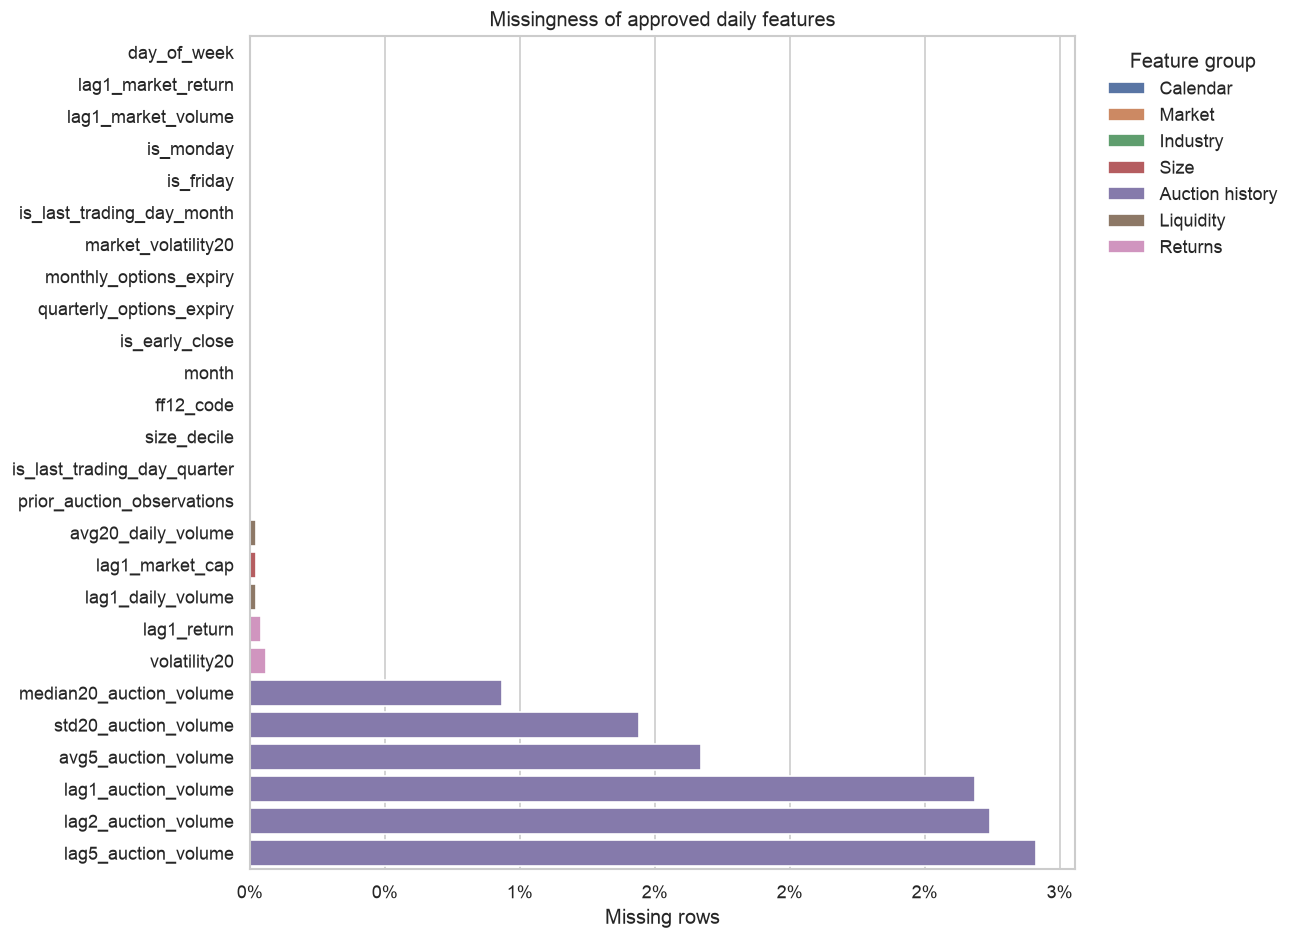

In [4]:
missing_queries = []
for feature in SAFE_FEATURES:
    missing_queries.append(f"""
        SELECT '{feature}' AS feature,
               count(*) AS rows,
               count(*) FILTER (WHERE \"{feature}\" IS NULL) AS missing,
               count(*) FILTER (WHERE \"{feature}\" IS NULL)::DOUBLE / count(*) AS missing_rate,
               count(DISTINCT \"{feature}\") AS distinct_values
        FROM read_parquet('{PANEL}')
    """)
feature_missingness = sql(" UNION ALL ".join(missing_queries)).sort_values("missing_rate", ascending=False)
feature_missingness = feature_missingness.merge(
    catalog[["variable", "group", "information_time"]], left_on="feature", right_on="variable", how="left"
).drop(columns="variable")
display(feature_missingness)
feature_missingness.to_csv(OUT / "feature_missingness.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 8))
plot_missing = feature_missingness.sort_values("missing_rate")
sns.barplot(data=plot_missing, y="feature", x="missing_rate", hue="group", dodge=False, ax=ax)
ax.xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax.set(title="Missingness of approved daily features", xlabel="Missing rows", ylabel="")
ax.legend(title="Feature group", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(OUT / "feature_missingness.png", bbox_inches="tight")
plt.show()

## Missingness by year

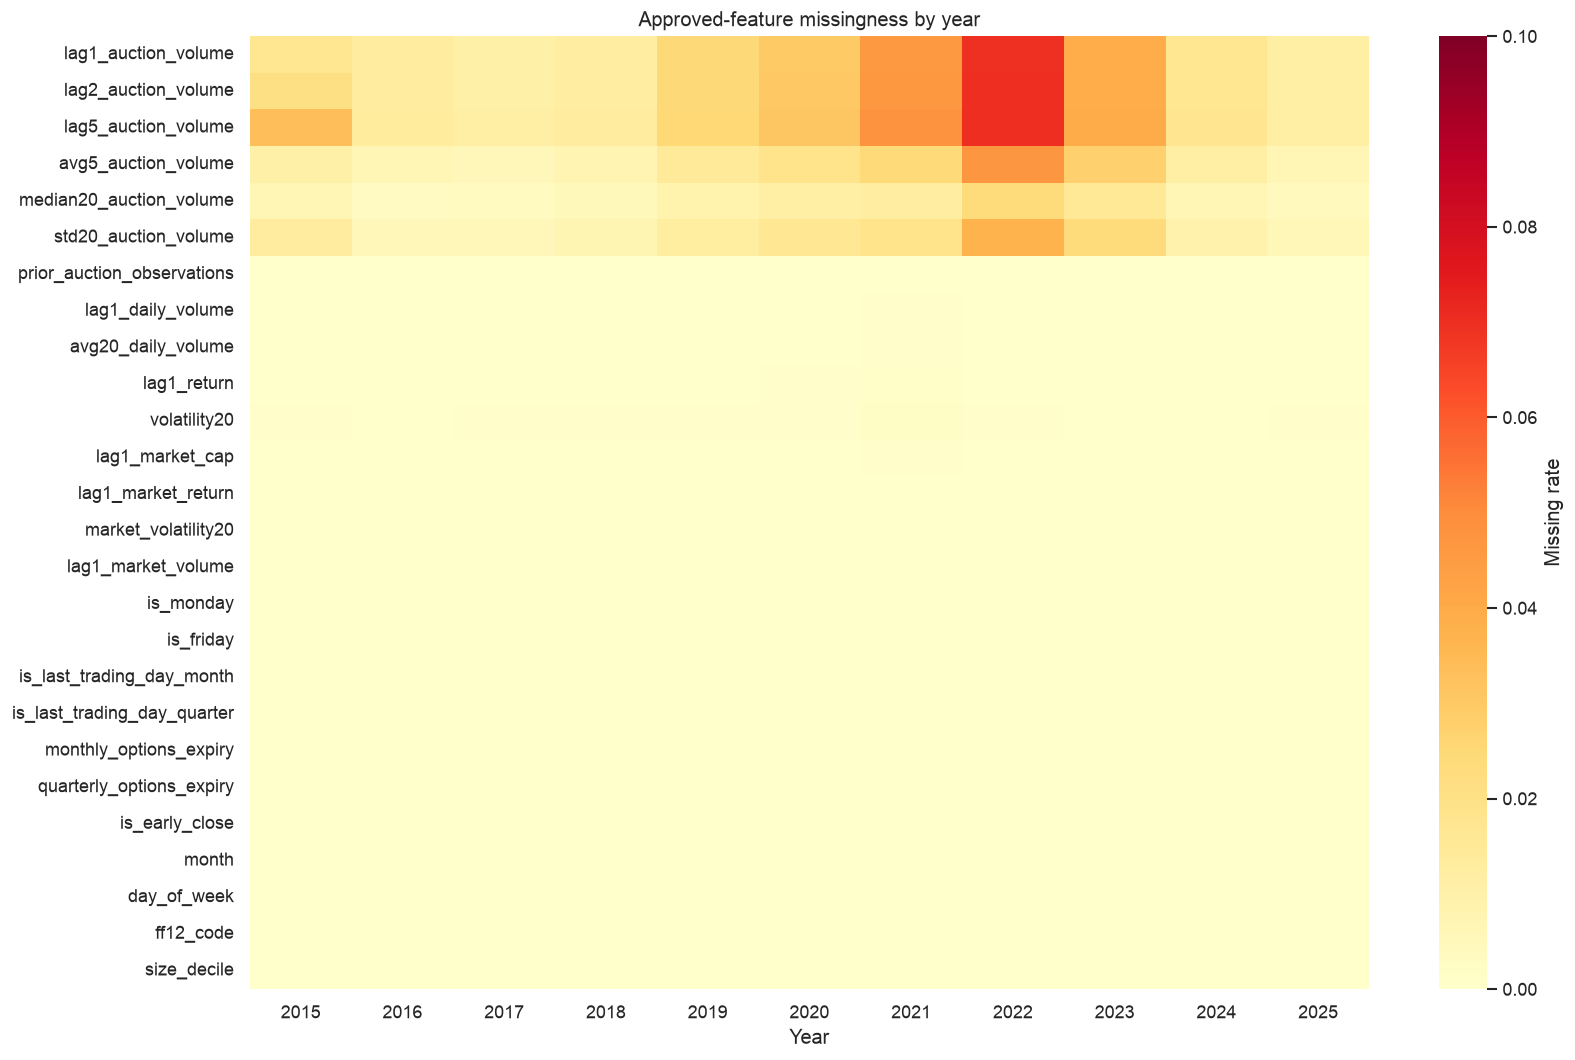

In [5]:
yearly_queries = []
for feature in SAFE_FEATURES:
    yearly_queries.append(f"""
        SELECT year, '{feature}' AS feature, count(*) AS rows,
               count(*) FILTER (WHERE \"{feature}\" IS NULL)::DOUBLE / count(*) AS missing_rate
        FROM read_parquet('{PANEL}') GROUP BY year
    """)
missing_by_year = sql(" UNION ALL ".join(yearly_queries))
missing_by_year.to_csv(OUT / "feature_missingness_by_year.csv", index=False)

heat = missing_by_year.pivot(index="feature", columns="year", values="missing_rate").loc[SAFE_FEATURES]
fig, ax = plt.subplots(figsize=(14, 9))
sns.heatmap(heat, cmap="YlOrRd", vmin=0, vmax=max(0.10, float(heat.max().max())), ax=ax,
            cbar_kws={"label": "Missing rate"})
ax.set(title="Approved-feature missingness by year", xlabel="Year", ylabel="")
fig.tight_layout()
fig.savefig(OUT / "feature_missingness_by_year.png", bbox_inches="tight")
plt.show()

## Numeric range and outlier audit

In [6]:
NUMERIC_FEATURES = [
    "lag1_auction_volume", "lag2_auction_volume", "lag5_auction_volume",
    "avg5_auction_volume", "median20_auction_volume", "std20_auction_volume",
    "prior_auction_observations", "lag1_daily_volume", "avg20_daily_volume",
    "lag1_return", "volatility20", "lag1_market_cap",
    "lag1_market_return", "market_volatility20", "lag1_market_volume",
]
summary_queries = []
for feature in NUMERIC_FEATURES:
    summary_queries.append(f"""
      SELECT '{feature}' AS feature,
             min(\"{feature}\") AS min,
             approx_quantile(\"{feature}\", 0.01) AS p01,
             approx_quantile(\"{feature}\", 0.50) AS median,
             approx_quantile(\"{feature}\", 0.99) AS p99,
             max(\"{feature}\") AS max,
             avg(\"{feature}\") AS mean,
             stddev_samp(\"{feature}\") AS std_dev,
             count(*) FILTER (WHERE \"{feature}\" = 0) AS zero_count,
             count(*) FILTER (WHERE \"{feature}\" < 0) AS negative_count
      FROM read_parquet('{PANEL}')
    """)
numeric_summary = sql(" UNION ALL ".join(summary_queries))
display(numeric_summary)
numeric_summary.to_csv(OUT / "numeric_feature_summary.csv", index=False)

,feature,min,p01,median,p99,max,mean,std_dev,zero_count,negative_count
0,lag1_auction_volume,1.0000,214.0000,"55,241.0000","2,100,052.0000","205,378,788.0000","189,738.3098","672,885.5165",0,0
1,lag2_auction_volume,1.0000,212.0000,"55,167.0000","2,101,454.0000","205,378,788.0000","189,698.2891","672,658.4933",0,0
2,lag5_auction_volume,1.0000,214.0000,"55,250.0000","2,086,286.0000","205,378,788.0000","189,719.5530","672,824.6895",0,0
3,avg5_auction_volume,1.0000,192.6675,"62,979.5300","1,934,663.3891","48,564,238.8000","187,846.6713","457,566.1202",0,0
4,median20_auction_volume,1.0000,121.8867,"49,119.1892","1,376,551.9435","32,528,401.0000","139,103.9048","298,504.4035",0,0
5,std20_auction_volume,0.0000,168.8312,"47,933.5051","1,928,992.6704","45,534,223.0416","165,954.3834","529,080.5192",3162,0
6,prior_auction_observations,0.0000,9.0000,990.0000,"2,718.0000","2,765.0000","1,118.5864",792.0773,6426,0
7,lag1_daily_volume,0.0000,392.8736,"638,575.1290","22,586,628.8164","1,253,254,000.0000","2,047,678.1016","6,112,429.2029",26216,0
8,avg20_daily_volume,0.0000,"2,822.5886","706,743.5433","21,297,829.6613","349,139,642.9000","2,047,244.0464","5,233,697.5882",676,0
9,lag1_return,-0.8824,-0.0837,0.0002,0.0902,6.9446,0.0005,0.0325,64353,1727931


## Redundancy and dependence among approved numeric features

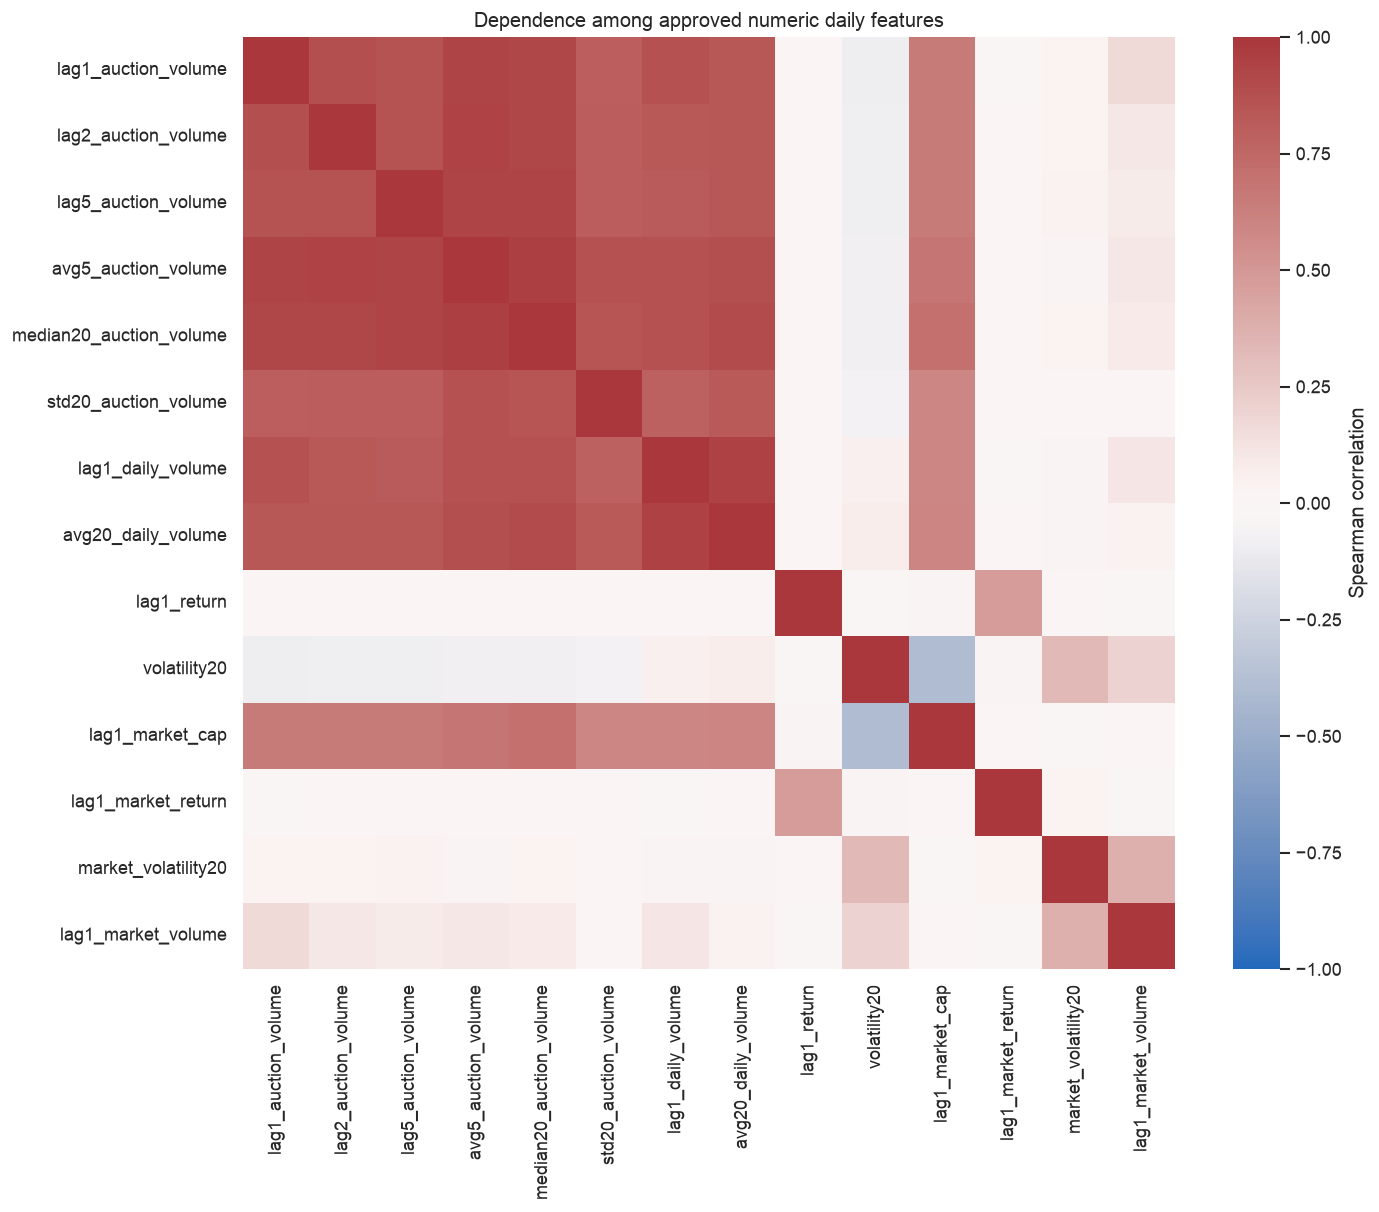

,level_0,level_1,spearman,absolute_spearman
46,avg5_auction_volume,median20_auction_volume,0.9541,0.9541
91,lag1_daily_volume,avg20_daily_volume,0.9525,0.9525
17,lag2_auction_volume,avg5_auction_volume,0.9382,0.9382
3,lag1_auction_volume,avg5_auction_volume,0.9350,0.9350
31,lag5_auction_volume,avg5_auction_volume,0.9344,0.9344
32,lag5_auction_volume,median20_auction_volume,0.9313,0.9313
18,lag2_auction_volume,median20_auction_volume,0.9281,0.9281
4,lag1_auction_volume,median20_auction_volume,0.9267,0.9267
63,median20_auction_volume,avg20_daily_volume,0.8963,0.8963
1,lag1_auction_volume,lag2_auction_volume,0.8808,0.8808


In [7]:
corr_features = [
    "lag1_auction_volume", "lag2_auction_volume", "lag5_auction_volume",
    "avg5_auction_volume", "median20_auction_volume", "std20_auction_volume",
    "lag1_daily_volume", "avg20_daily_volume", "lag1_return", "volatility20",
    "lag1_market_cap", "lag1_market_return", "market_volatility20", "lag1_market_volume",
]
sample = sql(f"""
SELECT {', '.join(corr_features)}
FROM read_parquet('{PANEL}')
USING SAMPLE 300000 ROWS (reservoir, 20261011)
""")
spearman = sample.rank(pct=True).corr()
spearman.to_csv(OUT / "safe_feature_spearman_correlations.csv")

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(spearman, cmap="vlag", center=0, vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"label": "Spearman correlation"})
ax.set(title="Dependence among approved numeric daily features")
fig.tight_layout()
fig.savefig(OUT / "safe_feature_correlation_heatmap.png", bbox_inches="tight")
plt.show()

pairs = (
    spearman.where(np.triu(np.ones(spearman.shape), k=1).astype(bool))
    .stack().rename("spearman").reset_index()
)
pairs["absolute_spearman"] = pairs["spearman"].abs()
high_pairs = pairs.sort_values("absolute_spearman", ascending=False).head(20)
display(high_pairs)
high_pairs.to_csv(OUT / "highest_feature_correlations.csv", index=False)

## Leakage guard and approved feature artifacts

In [8]:
panel_columns = [r[0] for r in con.execute(f"DESCRIBE SELECT * FROM read_parquet('{PANEL}')").fetchall()]
missing_from_panel = sorted(set(SAFE_FEATURES) - set(panel_columns))
forbidden_in_safe = sorted(FORBIDDEN_DAILY.intersection(SAFE_FEATURES))

guard = pd.DataFrame({
    "check": [
        "All approved features exist in canonical panel",
        "No known daily-leakage fields are approved",
        "Approved list excludes target fields",
    ],
    "passed": [
        not missing_from_panel,
        not forbidden_in_safe,
        not {"auction_volume", "log1p_auction_volume", "auction_to_adv20"}.intersection(SAFE_FEATURES),
    ],
    "details": [
        ", ".join(missing_from_panel) if missing_from_panel else "All present",
        ", ".join(forbidden_in_safe) if forbidden_in_safe else "None approved",
        "Targets excluded",
    ],
})
display(guard)
assert guard["passed"].all(), guard
guard.to_csv(OUT / "leakage_guard.csv", index=False)

approved = catalog[catalog["approved_daily_feature"]].copy()
approved.to_csv(OUT / "approved_daily_features.csv", index=False)
(OUT / "approved_daily_features.json").write_text(
    json.dumps({"features": SAFE_FEATURES, "target": "log1p_auction_volume"}, indent=2)
)
print(f"Saved {len(SAFE_FEATURES)} approved features.")

,check,passed,details
0,All approved features exist in canonical panel,True,All present
1,No known daily-leakage fields are approved,True,None approved
2,Approved list excludes target fields,True,Targets excluded


Saved 26 approved features.


## Coverage-aware feature readiness

In [9]:
readiness = feature_missingness[["feature", "group", "missing_rate", "distinct_values"]].copy()
readiness["status"] = np.select(
    [
        readiness["distinct_values"] <= 1,
        readiness["missing_rate"] > 0.10,
        readiness["missing_rate"] > 0.02,
    ],
    ["Do not use", "Needs missingness strategy", "Use with missing indicator / imputation"],
    default="Ready",
)
display(readiness)
readiness.to_csv(OUT / "feature_readiness.csv", index=False)

,feature,group,missing_rate,distinct_values,status
0,lag5_auction_volume,Auction history,0.0291,669072,Use with missing indicator / imputation
1,lag2_auction_volume,Auction history,0.0274,669598,Use with missing indicator / imputation
2,lag1_auction_volume,Auction history,0.0269,669847,Use with missing indicator / imputation
3,avg5_auction_volume,Auction history,0.0167,1525869,Ready
4,std20_auction_volume,Auction history,0.0144,3508543,Ready
5,median20_auction_volume,Auction history,0.0094,559420,Ready
6,volatility20,Returns,0.0006,3587697,Ready
7,lag1_return,Returns,0.0004,200512,Ready
8,lag1_daily_volume,Liquidity,0.0002,2012306,Ready
9,lag1_market_cap,Size,0.0002,3199432,Ready


## Decisions for the relationship notebook

1. Notebook 04 will use only the approved daily-feature artifact generated here.
2. Auction-history missingness must remain explicit; a missing prior auction is not a zero auction.
3. Rolling and lag features use information through `t-1` only.
4. Current-day CRSP outcomes, auction clearing information, and intraday checkpoint variables are prohibited in the daily model.
5. Highly correlated auction-history and liquidity features will be examined jointly rather than interpreted as independent causal effects.
6. Industry and size effects will be separated from within-stock relationships in the next notebook.